# Module 3 — Analyse exploratoire des données (EDA)

**Projet :** House Prices — Advanced Regression Techniques (Kaggle)
**Variable cible :** `SalePrice` (prix de vente, en dollars), disponible uniquement dans le jeu d'entraînement

## Objectif

Décrire les principales caractéristiques du marché immobilier étudié, mettre en évidence les tendances et les relations entre variables, et identifier les facteurs les plus susceptibles d'influencer le prix de vente.

## Périmètre et principes de travail

- Le notebook charge les jeux de données **déjà nettoyés** (`df_train_clean`, `df_test_clean`) produits à l'étape de préparation.
- Les analyses portent exclusivement sur le jeu d'entraînement ; le jeu de test n'est chargé que pour contrôle de cohérence.
- Aucune transformation n'est appliquée aux données dans ce notebook : il s'agit d'une analyse en lecture seule.

## Sommaire

1. Configuration et chargement des données
2. Distribution des prix de vente
3. Répartition des propriétés par quartier
4. Superficie habitable et prix
5. Qualité générale et prix
6. Année de construction et prix
7. Nombre de chambres et prix
8. Corrélations entre variables numériques et `SalePrice`
9. Synthèse et pistes pour la modélisation

## 1. Configuration et chargement des données

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Style graphique commun à l'ensemble du notebook
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

PRIMARY = "#2F5D8A"   # couleur principale
ACCENT = "#C0392B"    # couleur d'accentuation (médiane, droite de régression)

# Formateur d'axe pour les montants en dollars
USD = mtick.FuncFormatter(lambda x, _: f"${x:,.0f}")

In [2]:
# 2. Localisation du répertoire des données
candidate_paths = [
    Path.cwd() / "data" / "processed",
    Path.cwd().parent / "data" / "processed",
]

DATA_DIR = next((path for path in candidate_paths if path.is_dir()), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Dossier 'data/processed' introuvable. "
        "Placez les fichiers transformer dans data/processed ou adaptez DATA_DIR."
    )

print(f"Dossier des données : {DATA_DIR.resolve()}")

Dossier des données : C:\Users\hp\Downloads\house-prices-advanced-regression-techniques\notebooks\data\processed


In [3]:
# Chargement des jeux de données nettoyés
FILES = {"train": "df_train_clean.csv", "test": "df_test_clean.csv"}

dataframes = {}
for name, filename in FILES.items():
    file_path = DATA_DIR / filename
    if not file_path.is_file():
        raise FileNotFoundError(f"Fichier introuvable : {file_path}")
    dataframes[name] = pd.read_csv(file_path)

df_train_clean = dataframes["train"]
df_test_clean = dataframes["test"]

print(f"Train : {df_train_clean.shape[0]:,} lignes × {df_train_clean.shape[1]} colonnes")
print(f"Test  : {df_test_clean.shape[0]:,} lignes × {df_test_clean.shape[1]} colonnes")

Train : 1,460 lignes × 82 colonnes
Test  : 1,459 lignes × 81 colonnes


## 2. Distribution des prix de vente

**Objectif :** identifier les niveaux de prix les plus fréquents, la dispersion des valeurs et la présence éventuelle de prix exceptionnellement élevés ou faibles.

### 2.1. Statistiques descriptives

In [4]:
price = df_train_clean["SalePrice"]

summary = price.describe().to_frame("SalePrice").T
summary["asymétrie (skewness)"] = price.skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,asymétrie (skewness)
SalePrice,1460.0,180921.2,79442.5,34900.0,129975.0,163000.0,214000.0,755000.0,1.88


### 2.2. Histogramme

La ligne verticale indique le prix médian, indicateur plus robuste que la moyenne en présence de valeurs extrêmes.

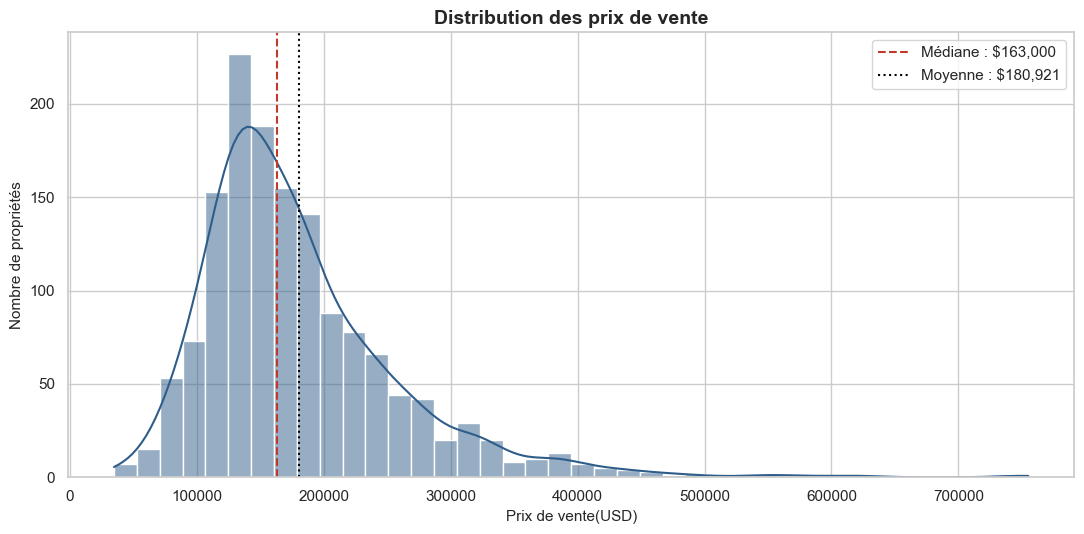

In [7]:
fig, ax = plt.subplots(figsize=(11, 5.5))

sns.histplot(price, bins=40, kde=True, color=PRIMARY, ax=ax)
ax.axvline(price.median(), color=ACCENT, linestyle="--",
           label=f"Médiane : ${price.median():,.0f}")
ax.axvline(price.mean(), color="black", linestyle=":",
           label=f"Moyenne : ${price.mean():,.0f}")

ax.set_title("Distribution des prix de vente")
ax.set_xlabel("Prix de vente(USD)")
ax.set_ylabel("Nombre de propriétés")
ax.legend()
plt.tight_layout()
plt.show()

### 2.3. Boîte à moustaches

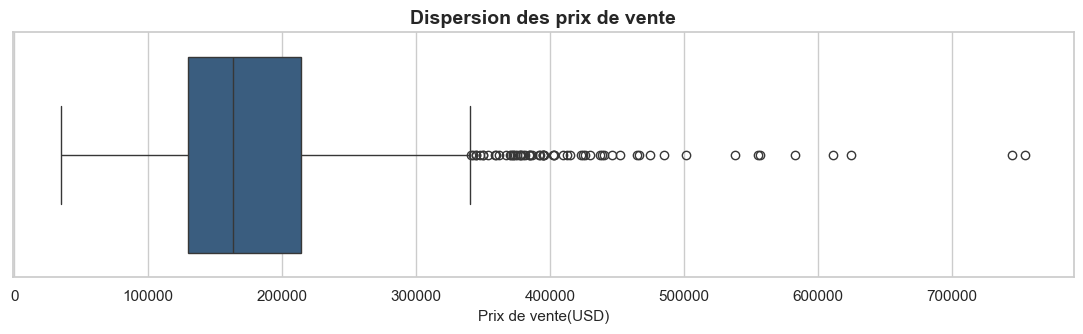

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.5))

sns.boxplot(x=price, color=PRIMARY, ax=ax)
ax.set_title("Dispersion des prix de vente")
ax.set_xlabel("Prix de vente(USD)")
plt.tight_layout()
plt.show()

### 2.4. Interprétation

- Le prix médian (163 000 $) est inférieur au prix moyen (≈ 180 921 $) : la distribution est **asymétrique à droite**, tirée vers le haut par un nombre limité de propriétés très chères (maximum : 755 000 $).
- La moitié des propriétés se vendent entre 129 975 $ et 214 000 $ (écart interquartile).
- Cette asymétrie suggère d'envisager une transformation logarithmique de `SalePrice` pour la modélisation.

## 3. Répartition des propriétés par quartier

**Objectif :** mesurer la représentation de chaque quartier (`Neighborhood`) dans le jeu de données.

### 3.1. Effectifs par quartier

In [9]:
neighborhood_counts = df_train_clean["Neighborhood"].value_counts()
neighborhood_share = (neighborhood_counts / neighborhood_counts.sum() * 100).round(1)

pd.DataFrame({"Effectif": neighborhood_counts, "Part (%)": neighborhood_share})

,Effectif,Part (%)
Neighborhood,,
NAmes,225,15.4
CollgCr,150,10.3
OldTown,113,7.7
Edwards,100,6.8
Somerst,86,5.9
Gilbert,79,5.4
NridgHt,77,5.3
Sawyer,74,5.1
NWAmes,73,5.0


### 3.2. Diagramme en barres

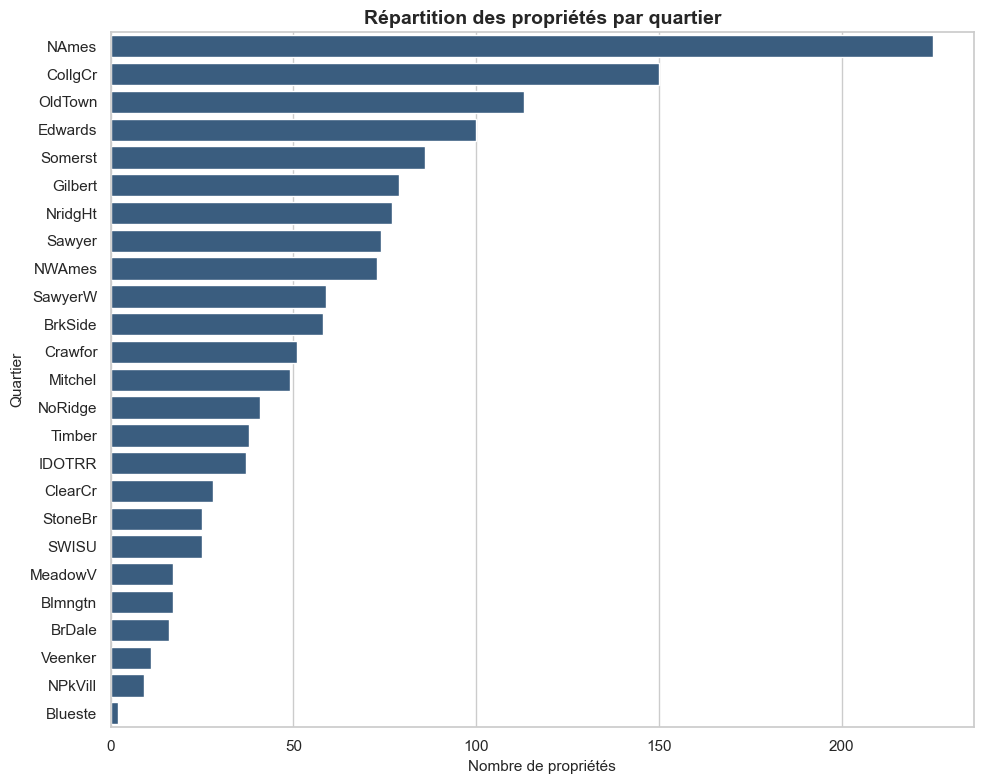

In [10]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.countplot(
    data=df_train_clean,
    y="Neighborhood",
    order=neighborhood_counts.index,
    color=PRIMARY,
    ax=ax,
)
ax.set_title("Répartition des propriétés par quartier")
ax.set_xlabel("Nombre de propriétés")
ax.set_ylabel("Quartier")
plt.tight_layout()
plt.show()

### 3.3. Interprétation

- **NAmes** est le quartier le plus représenté (225 propriétés, soit environ 15 % de l'échantillon), devant **CollgCr** (150) et **OldTown** (113).
- **Blueste** (2) et **NPkVill** (9) sont très peu représentés ; toute conclusion statistique sur ces quartiers est à interpréter avec prudence.
- La répartition est **déséquilibrée** : les trois premiers quartiers regroupent à eux seuls un tiers environ des observations.

Cette répartition conditionne la fiabilité d'une analyse du prix par quartier, qui sera approfondie dans la suite du projet.

## 4. Superficie habitable et prix de vente

**Objectif :** déterminer si les maisons disposant d'une grande surface habitable (`GrLivArea`, en pieds carrés) tendent à se vendre plus cher.

### 4.1. Statistiques descriptives

In [11]:
df_train_clean[["GrLivArea", "SalePrice"]].describe().round(2)

,GrLivArea,SalePrice
count,1460.00,1460.0
mean,1515.46,180921.2
std,525.48,79442.5
min,334.00,34900.0
25%,1129.50,129975.0
50%,1464.00,163000.0
75%,1776.75,214000.0
max,5642.00,755000.0


### 4.2. Nuage de points et droite de régression

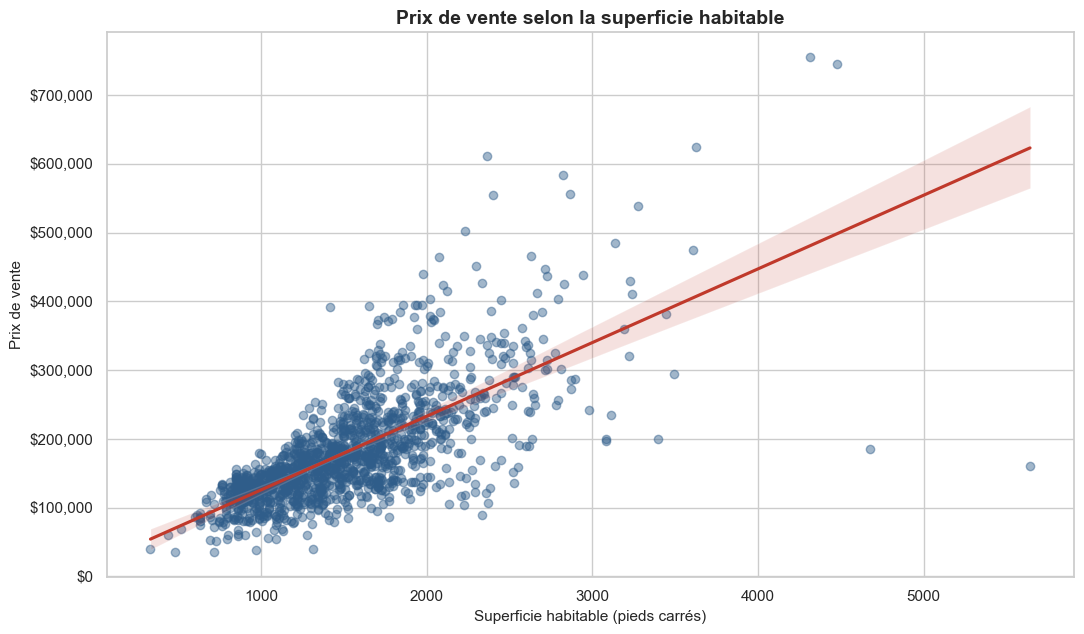

In [12]:
fig, ax = plt.subplots(figsize=(11, 6.5))

sns.regplot(
    data=df_train_clean, x="GrLivArea", y="SalePrice",
    scatter_kws={"alpha": 0.45, "color": PRIMARY},
    line_kws={"color": ACCENT},
    ax=ax,
)
ax.set_title("Prix de vente selon la superficie habitable")
ax.set_xlabel("Superficie habitable (pieds carrés)")
ax.set_ylabel("Prix de vente")
ax.yaxis.set_major_formatter(USD)
plt.tight_layout()
plt.show()

### 4.3. Coefficient de corrélation et valeurs atypiques

In [13]:
corr_area = df_train_clean["GrLivArea"].corr(df_train_clean["SalePrice"])
print(f"Corrélation de Pearson GrLivArea / SalePrice : {corr_area:.3f}")

# Grandes surfaces vendues à un prix relativement bas (valeurs atypiques potentielles)
outliers = (
    df_train_clean.loc[df_train_clean["GrLivArea"] > 4000, ["GrLivArea", "SalePrice"]]
    .sort_values("GrLivArea", ascending=False)
)
print(f"\nPropriétés de plus de 4 000 pi² : {len(outliers)}")
outliers

Corrélation de Pearson GrLivArea / SalePrice : 0.709

Propriétés de plus de 4 000 pi² : 4


,GrLivArea,SalePrice
1298,5642,160000
523,4676,184750
1182,4476,745000
691,4316,755000


### 4.4. Interprétation

- Il existe une **relation positive et marquée** entre superficie et prix (r = 0,709).
- Les propriétés dépassant 4 000 pi² (tableau ci-dessus) sont peu nombreuses ; celles dont le prix est anormalement bas par rapport à leur surface peuvent exercer un effet de levier sur la droite de régression.
- **Recommandation :** examiner ces observations avant la modélisation et décider, de façon documentée, de les conserver ou de les écarter.

## 5. Qualité générale du bâtiment et prix de vente

**Objectif :** mesurer l'association entre `OverallQual` (évaluation de la qualité des matériaux et des finitions, de 1 à 10) et `SalePrice`.

### 5.1. Effectifs et prix moyen par niveau de qualité

In [14]:
quality_summary = (
    df_train_clean.groupby("OverallQual")["SalePrice"]
    .agg(Effectif="count", Prix_moyen="mean", Prix_median="median")
    .round(0)
)
quality_summary

,Effectif,Prix_moyen,Prix_median
OverallQual,,,
1,2,50150.0,50150.0
2,3,51770.0,60000.0
3,20,87474.0,86250.0
4,116,108421.0,108000.0
5,397,133523.0,133000.0
6,374,161603.0,160000.0
7,319,207716.0,200141.0
8,168,274736.0,269750.0
9,43,367513.0,345000.0


### 5.2. Boîtes à moustaches par niveau de qualité

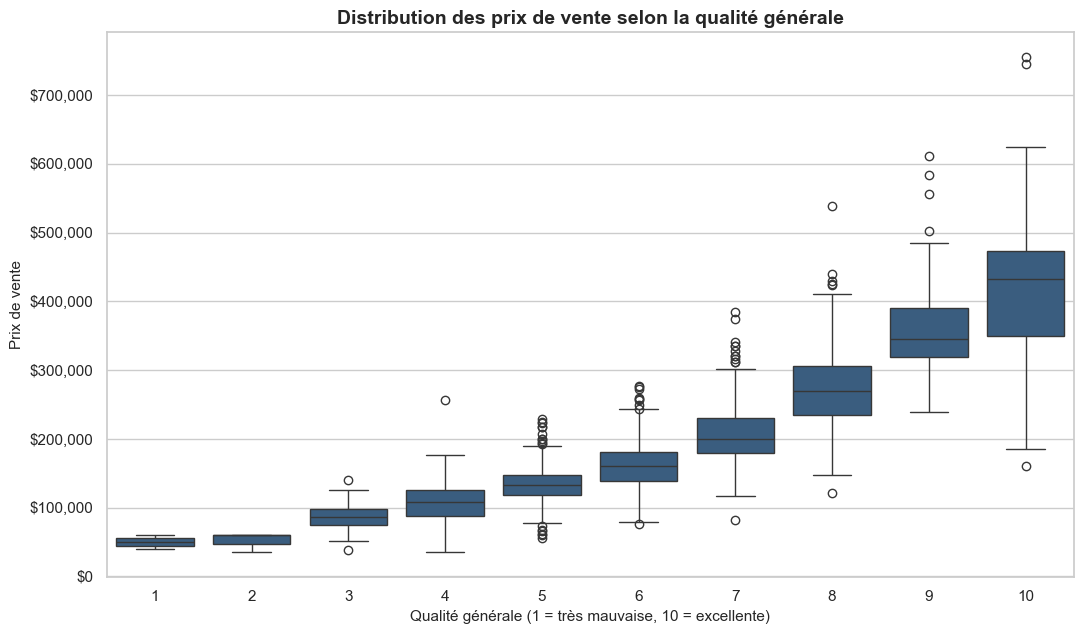

In [15]:
fig, ax = plt.subplots(figsize=(11, 6.5))

sns.boxplot(data=df_train_clean, x="OverallQual", y="SalePrice",
            color=PRIMARY, ax=ax)
ax.set_title("Distribution des prix de vente selon la qualité générale")
ax.set_xlabel("Qualité générale (1 = très mauvaise, 10 = excellente)")
ax.set_ylabel("Prix de vente")
ax.yaxis.set_major_formatter(USD)
plt.tight_layout()
plt.show()

In [16]:
corr_quality = df_train_clean["OverallQual"].corr(df_train_clean["SalePrice"])
print(f"Corrélation de Pearson OverallQual / SalePrice : {corr_quality:.3f}")

Corrélation de Pearson OverallQual / SalePrice : 0.791


### 5.3. Interprétation

- Le prix moyen **augmente de façon continue** avec la qualité : d'environ 50 000 $ (niveau 1) à plus de 438 000 $ (niveau 10).
- Corrélation de **0,791**, la plus élevée de toutes les variables numériques.
- Les niveaux extrêmes (1, 2 et 10) reposent sur très peu d'observations (respectivement 2, 3 et 18) ; la plupart des propriétés se situent entre les niveaux 4 et 8.
- La dispersion des prix augmente avec la qualité : à niveau égal, les écarts de prix sont plus importants dans les catégories supérieures.

## 6. Année de construction et prix de vente

**Objectif :** évaluer si l'ancienneté du bâtiment (`YearBuilt`) est associée à sa valeur.

### 6.1. Statistiques descriptives

In [17]:
df_train_clean["YearBuilt"].describe().round(1)

count    1460.0
mean     1971.3
std        30.2
min      1872.0
25%      1954.0
50%      1973.0
75%      2000.0
max      2010.0
Name: YearBuilt, dtype: float64

In [18]:
mean_price_by_year = (
    df_train_clean.groupby("YearBuilt")["SalePrice"].mean().reset_index()
)
corr_year = df_train_clean["YearBuilt"].corr(df_train_clean["SalePrice"])
print(f"Corrélation de Pearson YearBuilt / SalePrice : {corr_year:.3f}")

Corrélation de Pearson YearBuilt / SalePrice : 0.523


### 6.2. Visualisations

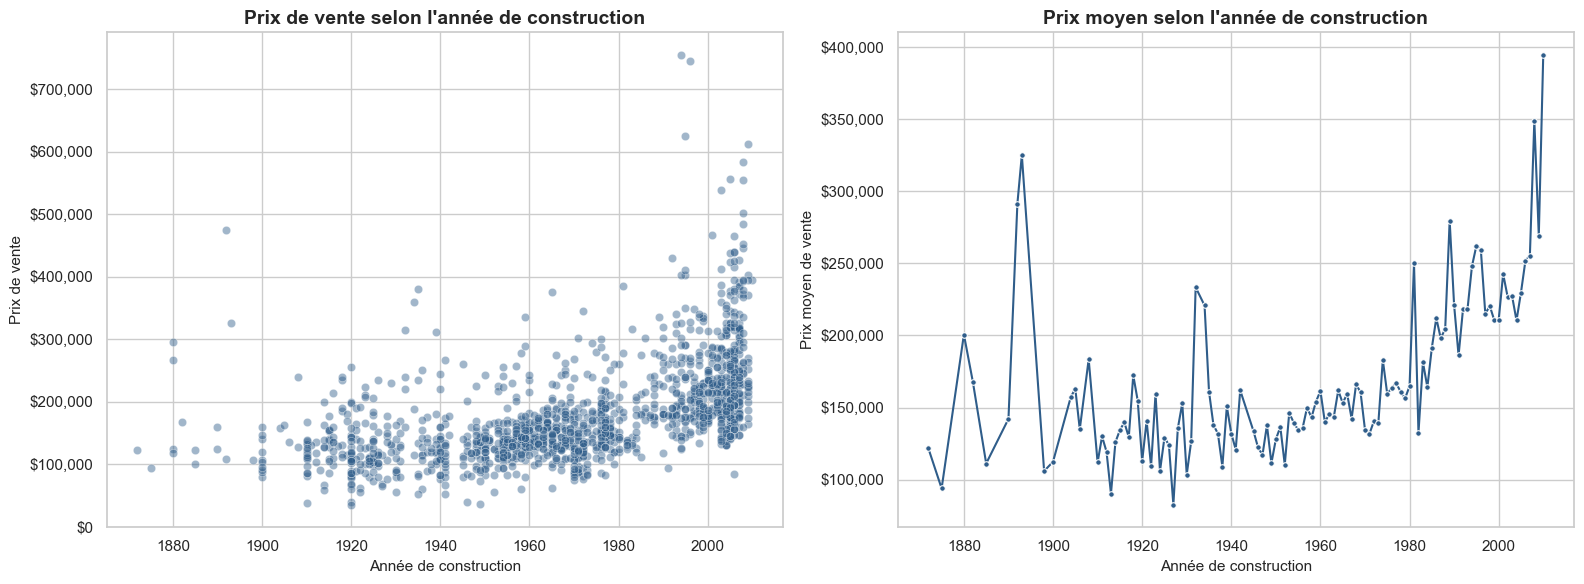

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df_train_clean, x="YearBuilt", y="SalePrice",
                alpha=0.45, color=PRIMARY, ax=axes[0])
axes[0].set_title("Prix de vente selon l'année de construction")
axes[0].set_xlabel("Année de construction")
axes[0].set_ylabel("Prix de vente")
axes[0].yaxis.set_major_formatter(USD)

sns.lineplot(data=mean_price_by_year, x="YearBuilt", y="SalePrice",
             marker="o", markersize=4, color=PRIMARY, ax=axes[1])
axes[1].set_title("Prix moyen selon l'année de construction")
axes[1].set_xlabel("Année de construction")
axes[1].set_ylabel("Prix moyen de vente")
axes[1].yaxis.set_major_formatter(USD)

plt.tight_layout()
plt.show()

### 6.3. Interprétation

- Les propriétés vont de 1872 à 2010 (médiane : 1973).
- Relation positive **modérée** (r = 0,523) : les constructions récentes se vendent en moyenne plus cher.
- La courbe du prix moyen est irrégulière pour les périodes anciennes, car certaines années ne comptent que très peu de ventes ; elle doit être lue comme une tendance générale et non année par année.

## 7. Nombre de chambres et prix de vente

**Objectif :** étudier l'évolution du prix selon le nombre de chambres hors sous-sol (`BedroomAbvGr`).

### 7.1. Statistiques par catégorie

In [20]:
bedroom_summary = (
    df_train_clean.groupby("BedroomAbvGr")["SalePrice"]
    .agg(Effectif="count", Prix_moyen="mean", Prix_median="median",
         Prix_min="min", Prix_max="max")
    .round(0)
)
bedroom_summary

,Effectif,Prix_moyen,Prix_median,Prix_min,Prix_max
BedroomAbvGr,,,,,
0,6,221493.0,202500.0,108959,385000
1,50,173162.0,145250.0,35311,501837
2,358,158198.0,137250.0,34900,611657
3,804,181057.0,169945.0,40000,451950
4,213,220421.0,193500.0,64500,755000
5,21,180819.0,161500.0,81000,320000
6,7,143779.0,141000.0,119000,200000
8,1,200000.0,200000.0,200000,200000


### 7.2. Boîtes à moustaches

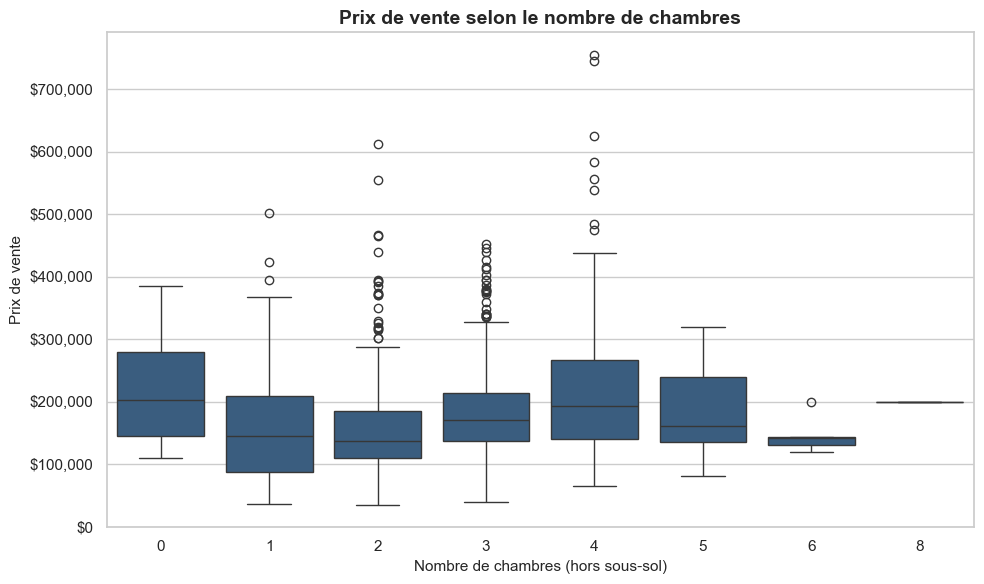

In [21]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(data=df_train_clean, x="BedroomAbvGr", y="SalePrice",
            color=PRIMARY, ax=ax)
ax.set_title("Prix de vente selon le nombre de chambres")
ax.set_xlabel("Nombre de chambres (hors sous-sol)")
ax.set_ylabel("Prix de vente")
ax.yaxis.set_major_formatter(USD)
plt.tight_layout()
plt.show()

### 7.3. Interprétation

- La relation est **faible** (r = 0,168) et **non monotone** : le prix médian passe de 137 250 $ (2 chambres) à 169 945 $ (3) puis 193 500 $ (4), mais recule pour 5 et 6 chambres.
- Les catégories 0, 5, 6 et 8 comptent moins de 25 observations chacune ; les comparaisons y sont peu fiables.
- Le nombre de chambres, pris isolément, est un prédicteur modeste ; il est probablement partiellement capté par la superficie.

## 8. Corrélations entre variables numériques et `SalePrice`

**Objectif :** identifier les variables numériques les plus associées au prix de vente (corrélation de Pearson, qui mesure uniquement les relations *linéaires*).

### 8.1. Calcul des corrélations

In [22]:
numeric_cols = (
    df_train_clean.select_dtypes(include="number")
    .drop(columns=["Id"], errors="ignore")
)
print(f"Nombre de variables numériques : {numeric_cols.shape[1]}")

correlation_matrix = numeric_cols.corr()
corr_with_price = (
    correlation_matrix["SalePrice"].drop("SalePrice").sort_values(ascending=False)
)
corr_with_price.round(3).to_frame("Corrélation avec SalePrice")

Nombre de variables numériques : 38


,Corrélation avec SalePrice
OverallQual,0.791
GrLivArea,0.709
GarageCars,0.640
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
FullBath,0.561
TotRmsAbvGrd,0.534
YearBuilt,0.523
YearRemodAdd,0.507


### 8.2. Ensemble des variables numériques

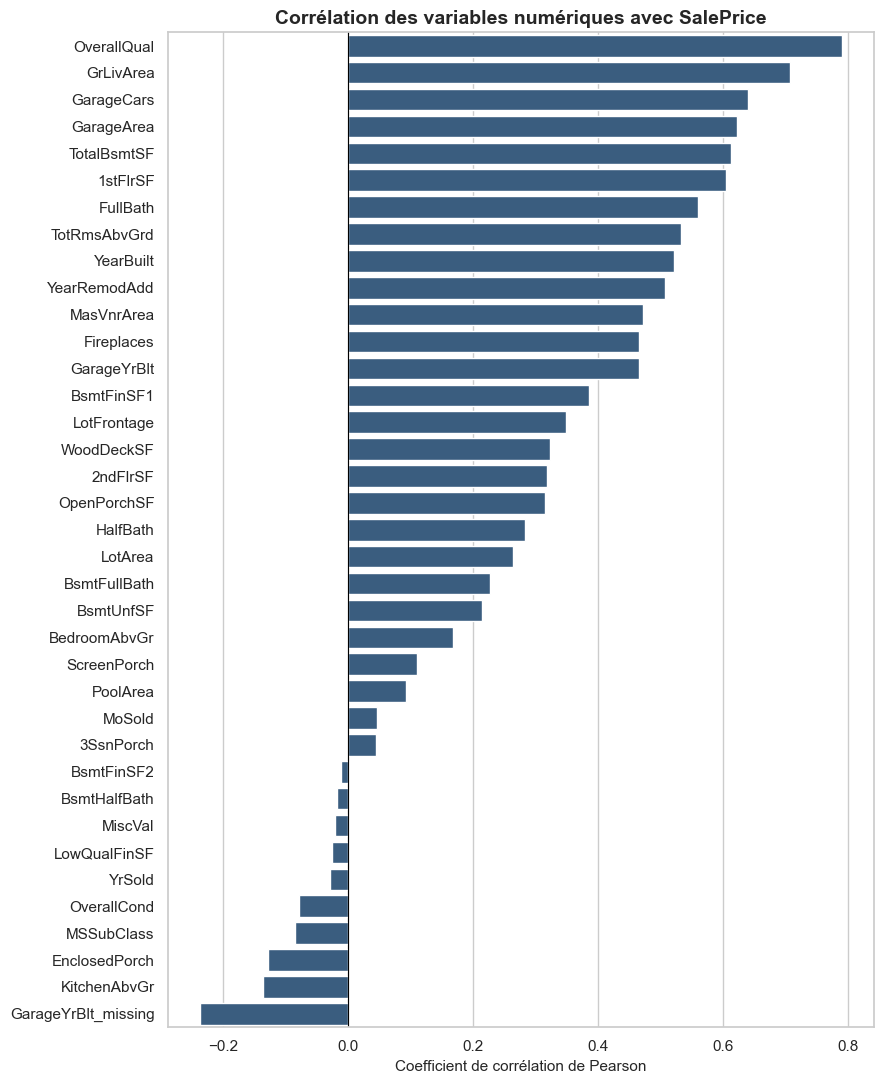

In [23]:
fig, ax = plt.subplots(figsize=(9, 11))

sns.barplot(x=corr_with_price.values, y=corr_with_price.index,
            color=PRIMARY, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Corrélation des variables numériques avec SalePrice")
ax.set_xlabel("Coefficient de corrélation de Pearson")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 8.3. Matrice de corrélation complète

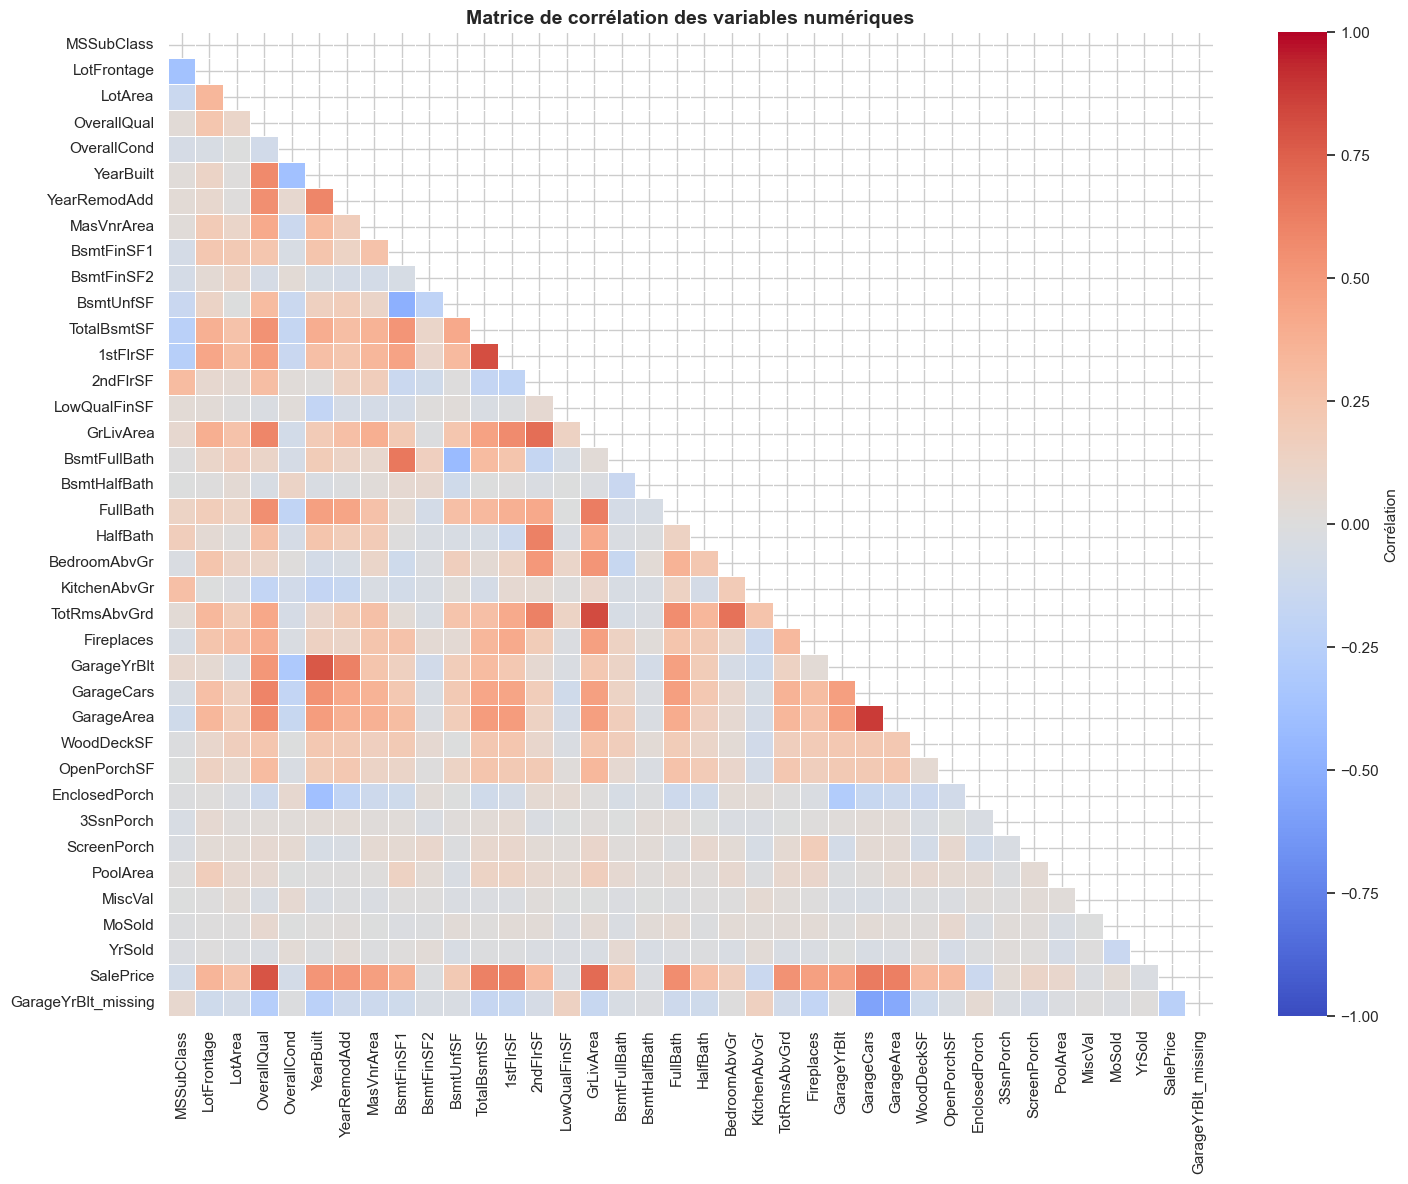

In [24]:
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(correlation_matrix, mask=mask, cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.4, cbar_kws={"label": "Corrélation"},
            ax=ax)
ax.set_title("Matrice de corrélation des variables numériques")
plt.tight_layout()
plt.show()

### 8.4. Les 15 variables les plus associées au prix (valeur absolue)

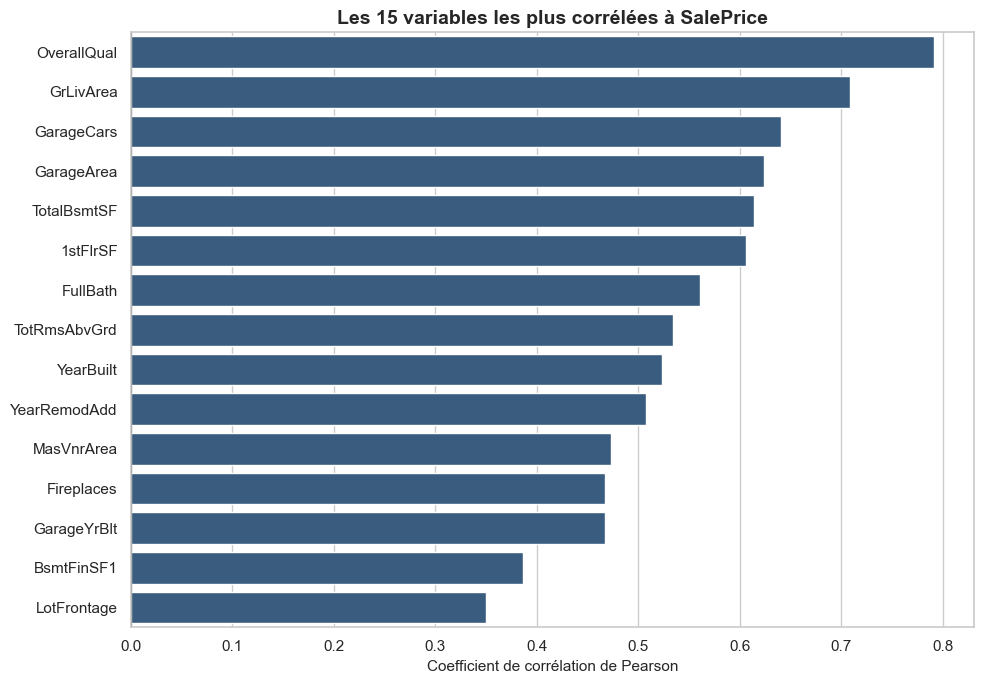

,Corrélation avec SalePrice
OverallQual,0.791
GrLivArea,0.709
GarageCars,0.640
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
FullBath,0.561
TotRmsAbvGrd,0.534
YearBuilt,0.523
YearRemodAdd,0.507


In [25]:
top15 = corr_with_price.reindex(corr_with_price.abs().sort_values(ascending=False).index).head(15)

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=top15.values, y=top15.index, color=PRIMARY, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Les 15 variables les plus corrélées à SalePrice")
ax.set_xlabel("Coefficient de corrélation de Pearson")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

top15.round(3).to_frame("Corrélation avec SalePrice")

### 8.5. Relations avec les trois variables principales

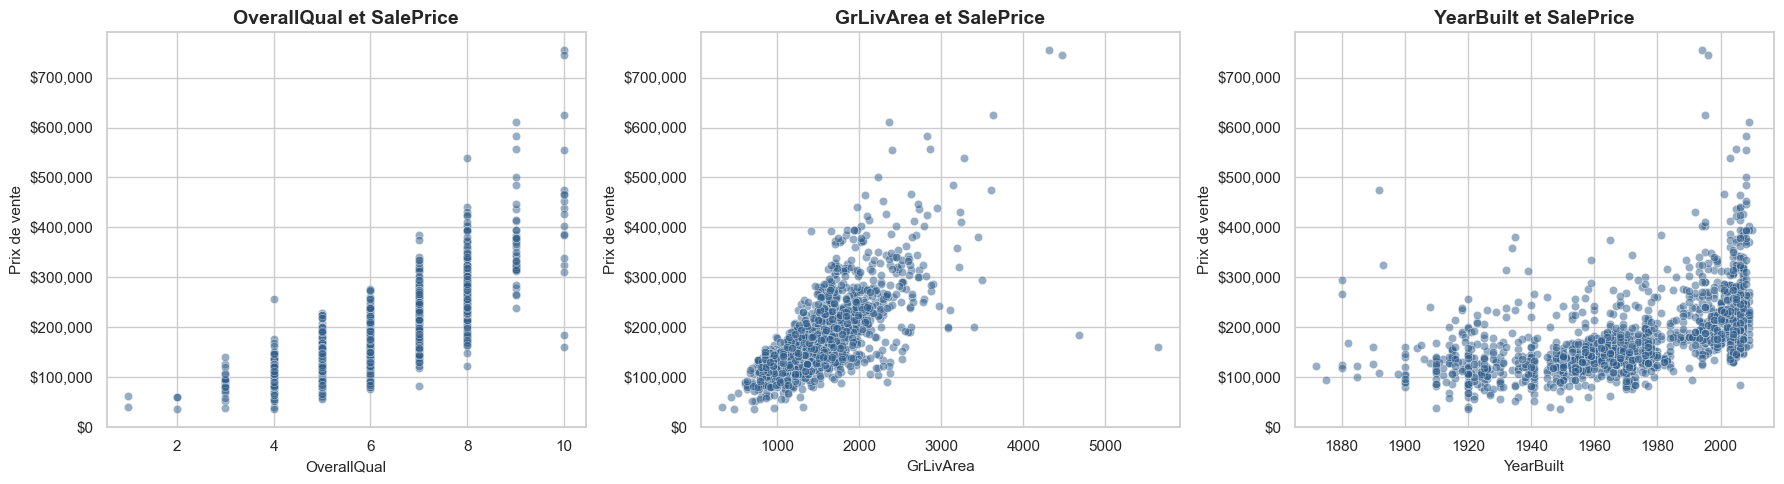

In [26]:
key_variables = ["OverallQual", "GrLivArea", "YearBuilt"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, variable in zip(axes, key_variables):
    sns.scatterplot(data=df_train_clean, x=variable, y="SalePrice",
                    alpha=0.5, color=PRIMARY, ax=ax)
    ax.set_title(f"{variable} et SalePrice")
    ax.set_ylabel("Prix de vente")
    ax.yaxis.set_major_formatter(USD)

plt.tight_layout()
plt.show()

### 8.6. Interprétation

- Les variables les plus corrélées au prix sont `OverallQual` (0,79), `GrLivArea` (0,71), `GarageCars` (0,64), `GarageArea` (0,62) et `TotalBsmtSF` (0,61).
- Plusieurs variables mesurent des réalités proches et sont **fortement corrélées entre elles** (par exemple `GarageCars` et `GarageArea`, `1stFlrSF` et `TotalBsmtSF`) : cette multicolinéarité devra être maîtrisée pour les modèles linéaires.
- `GarageYrBlt_missing` (−0,24) est un indicateur de valeur manquante pour `GarageYrBlt` (vraisemblablement une absence de garage) ; son signe négatif est cohérent avec les corrélations positives des variables de garage.
- La corrélation de Pearson ne capture pas les relations non linéaires ni l'effet des variables catégorielles (quartier, par exemple).

## 9. Synthèse et pistes pour la modélisation

| Constat | Élément chiffré | Implication |
|---|---|---|
| Distribution du prix asymétrique à droite | Médiane 163 000 $ vs moyenne ≈ 180 921 $ | Envisager une transformation logarithmique de `SalePrice` |
| Qualité générale : facteur le plus associé au prix | r = 0,791 | Variable prioritaire pour le modèle |
| Superficie habitable fortement associée au prix | r = 0,709 | Variable prioritaire ; examiner les valeurs atypiques (> 4 000 pi²) |
| Année de construction : relation modérée | r = 0,523 | Variable utile, éventuellement transformée en âge du bien |
| Nombre de chambres : relation faible | r = 0,168 | Intérêt limité en variable isolée |
| Variables fortement corrélées entre elles | Garage, sous-sol, 1er étage | Surveiller la multicolinéarité |
| Quartiers déséquilibrés | 2 à 225 observations selon le quartier | Prudence sur les quartiers à faible effectif |

**Prochaines étapes suggérées :** analyse du prix par quartier et par variable catégorielle, traitement documenté des valeurs atypiques, puis ingénierie des variables et modélisation.